# 1. Identify the ML Approach and Algorithms Relevant to the Dataset and Expected Output of the Application

## Project Title

**Kenyan Food Identification Using a Multi-Label Image Classification Model**

## 1.1 Problem Definition

The objective of this project is to develop a machine learning model capable of identifying different Kenyan food items from images.

Unlike a traditional single-label classification model, where each image is assigned only one category, this project uses a multi-label classification approach. This allows an image to be associated with multiple food categories where necessary.

The model is designed to recognise food items based on their visual characteristics and produce a probability score for each food category.

## 1.2 Machine Learning Approach

A supervised deep learning approach was selected for this project.

The model uses labelled food images to learn visual patterns associated with different Kenyan food categories. These patterns include colour, texture, shape and other visual characteristics.

A multi-label classification approach was adopted because some food images may contain more than one food item.

## 1.3 Selected Algorithm

MobileNetV2 was selected as the base architecture for the model.

MobileNetV2 is a Convolutional Neural Network (CNN) architecture designed to extract useful visual features from images while maintaining computational efficiency.

Transfer learning was used to take advantage of the visual features learned by the pre-trained MobileNetV2 network. This provides a foundation for recognising Kenyan food categories without having to develop an entire image recognition network from scratch.

The final classification layer was configured to produce 22 outputs, corresponding to the food labels used during model development.

## 1.4 Expected Model Output

For each input image, the model produces a probability score for each of the 22 food categories.

Since this is a multi-label classification problem, multiple categories can be predicted for a single image rather than restricting the prediction to only one category.

These probability scores can then be used to determine which food categories are present in the image.


# 2. Dataset Exploration (EDA)

## 2.1 Dataset Description

The dataset used in this project consists of images of Kenyan
food items collected and prepared for a multi-label image
classification task.

The project initially used a dataset of 13 Kenyan food categories
containing 6,462 standardised images. However, the original
dataset presented a limitation: some images contained multiple
food items but were assigned only one category based on their
folder location.

To address this issue, the dataset was reviewed and an annotation
process was introduced. Images were examined individually, and
multiple food labels could be assigned to a single image where
appropriate.

The final annotated dataset contained 639 images and 22 food
labels. Each image was represented using binary labels, where
1 indicated the presence of a food category and 0 indicated
its absence.

This approach allowed the model to learn from images containing
more than one identifiable food item.

The final annotated dataset was stored in a CSV file named
`combined_annotations_final_v1.csv`, which was used to prepare
the training, validation and testing datasets.

### 2.2 Distribution of Food Labels

After completing the annotation process, the distribution of
the 22 food labels was examined.

Unlike a traditional multi-class dataset, where each image
belongs to exactly one category, a multi-label dataset allows
an image to contain several food labels.

Therefore, the total number of positive labels does not
necessarily equal the total number of images.

The distribution was examined to identify which food categories
were more frequently represented and which had fewer examples.
This was important because differences in label frequency
could influence the model's ability to recognise individual
food categories.

Total number of images: 639
Number of food labels: 22
Total positive label assignments: 1035


,Food Category,Number of Images
0,sukumawiki,81
1,ugali,74
2,kachumbari,73
3,githeri,67
4,kukuchoma,66
5,chapati,62
6,nyamachoma,61
7,matoke,58
8,bhaji,52
9,avocado,50


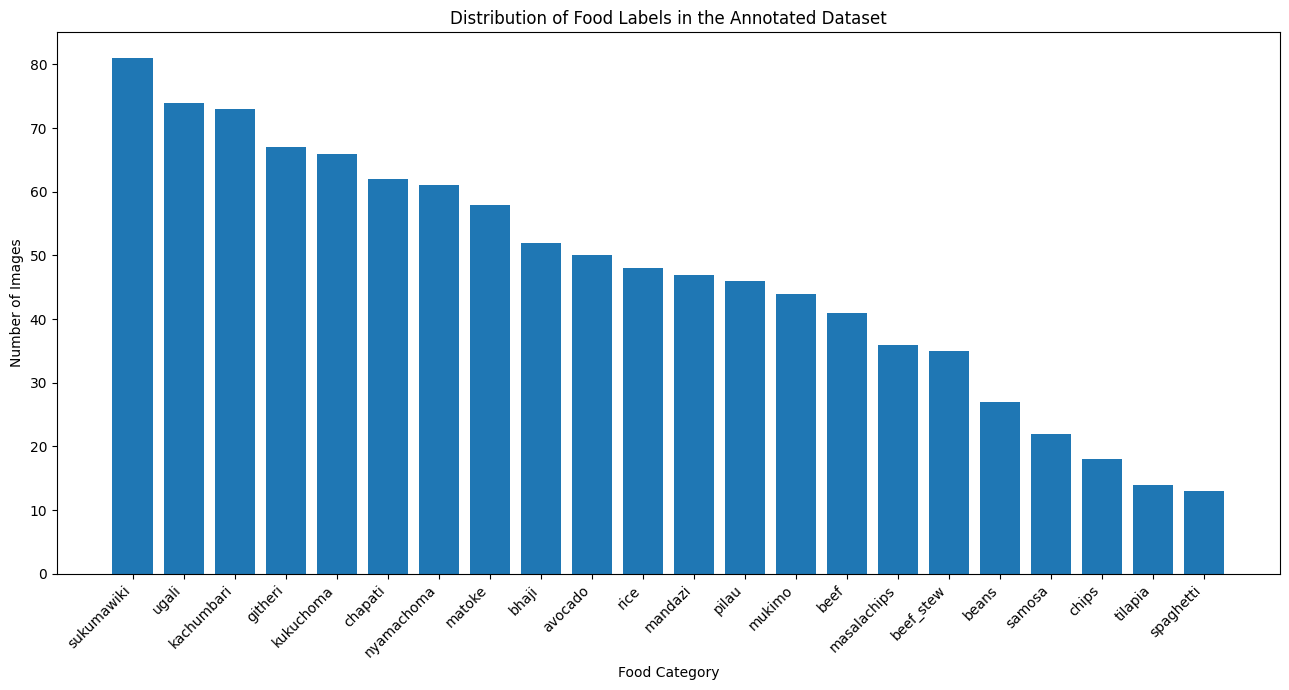

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Path to the final annotated dataset
CSV_PATH = "/content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_final_v1.csv"

# Load annotations
df = pd.read_csv(CSV_PATH)

# Food label columns in the dataset
label_columns = [
    "spaghetti", "tilapia", "chips", "samosa", "beans",
    "beef_stew", "masalachips", "beef", "mukimo", "pilau",
    "mandazi", "rice", "avocado", "bhaji", "matoke",
    "nyamachoma", "chapati", "kukuchoma", "githeri",
    "kachumbari", "ugali", "sukumawiki"
]

# Calculate the number of positive examples for each label
class_counts = df[label_columns].sum().sort_values(ascending=False)

# Create a summary table
distribution_df = pd.DataFrame({
    "Food Category": class_counts.index,
    "Number of Images": class_counts.values
})

# Display dataset statistics
print("Total number of images:", len(df))
print("Number of food labels:", len(label_columns))
print("Total positive label assignments:", int(class_counts.sum()))

display(distribution_df)

# Plot label distribution
plt.figure(figsize=(13, 7))

plt.bar(
    distribution_df["Food Category"],
    distribution_df["Number of Images"]
)

plt.title("Distribution of Food Labels in the Annotated Dataset")
plt.xlabel("Food Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 2.3 Observations from Exploratory Data Analysis

The exploration of the annotated dataset revealed the following:

1. The final dataset contains 639 images distributed across
   22 food labels.

2. Sukuma Wiki has the highest number of positive examples,
   with 81 images.

3. Spaghetti has the lowest number of positive examples,
   with only 13 images.

4. The dataset contains an uneven distribution of food labels.
   Some categories have considerably more examples than others.
   This could affect the model's ability to learn less frequently
   represented food categories.

5. The dataset contains 1,035 positive label assignments across
   the 639 images. This demonstrates that some images contain
   multiple food categories.

6. The multi-label annotation approach provides a more accurate
   representation of images containing several food items,
   compared to assigning each image only one category.

These observations highlighted the importance of considering
class imbalance and using a multi-label classification approach
during model development.

### 2.4 Visual Inspection of Images

Visual inspection was carried out to better understand the
images included in the annotated dataset.

The images were reviewed to identify the different food items,
their visual characteristics and the presence of multiple food
categories within individual images.

This process was particularly important because some Kenyan
foods have similar visual appearances. For example, rice and
pilau can be difficult to distinguish in certain images, while
githeri and beans may also share visual similarities.

The inspection process also helped identify images containing
multiple food items, ensuring that the annotation process
accounted for all identifiable food categories rather than
assigning only one label to each image.

A selection of images from the dataset was displayed to
illustrate the visual variation present in the data.

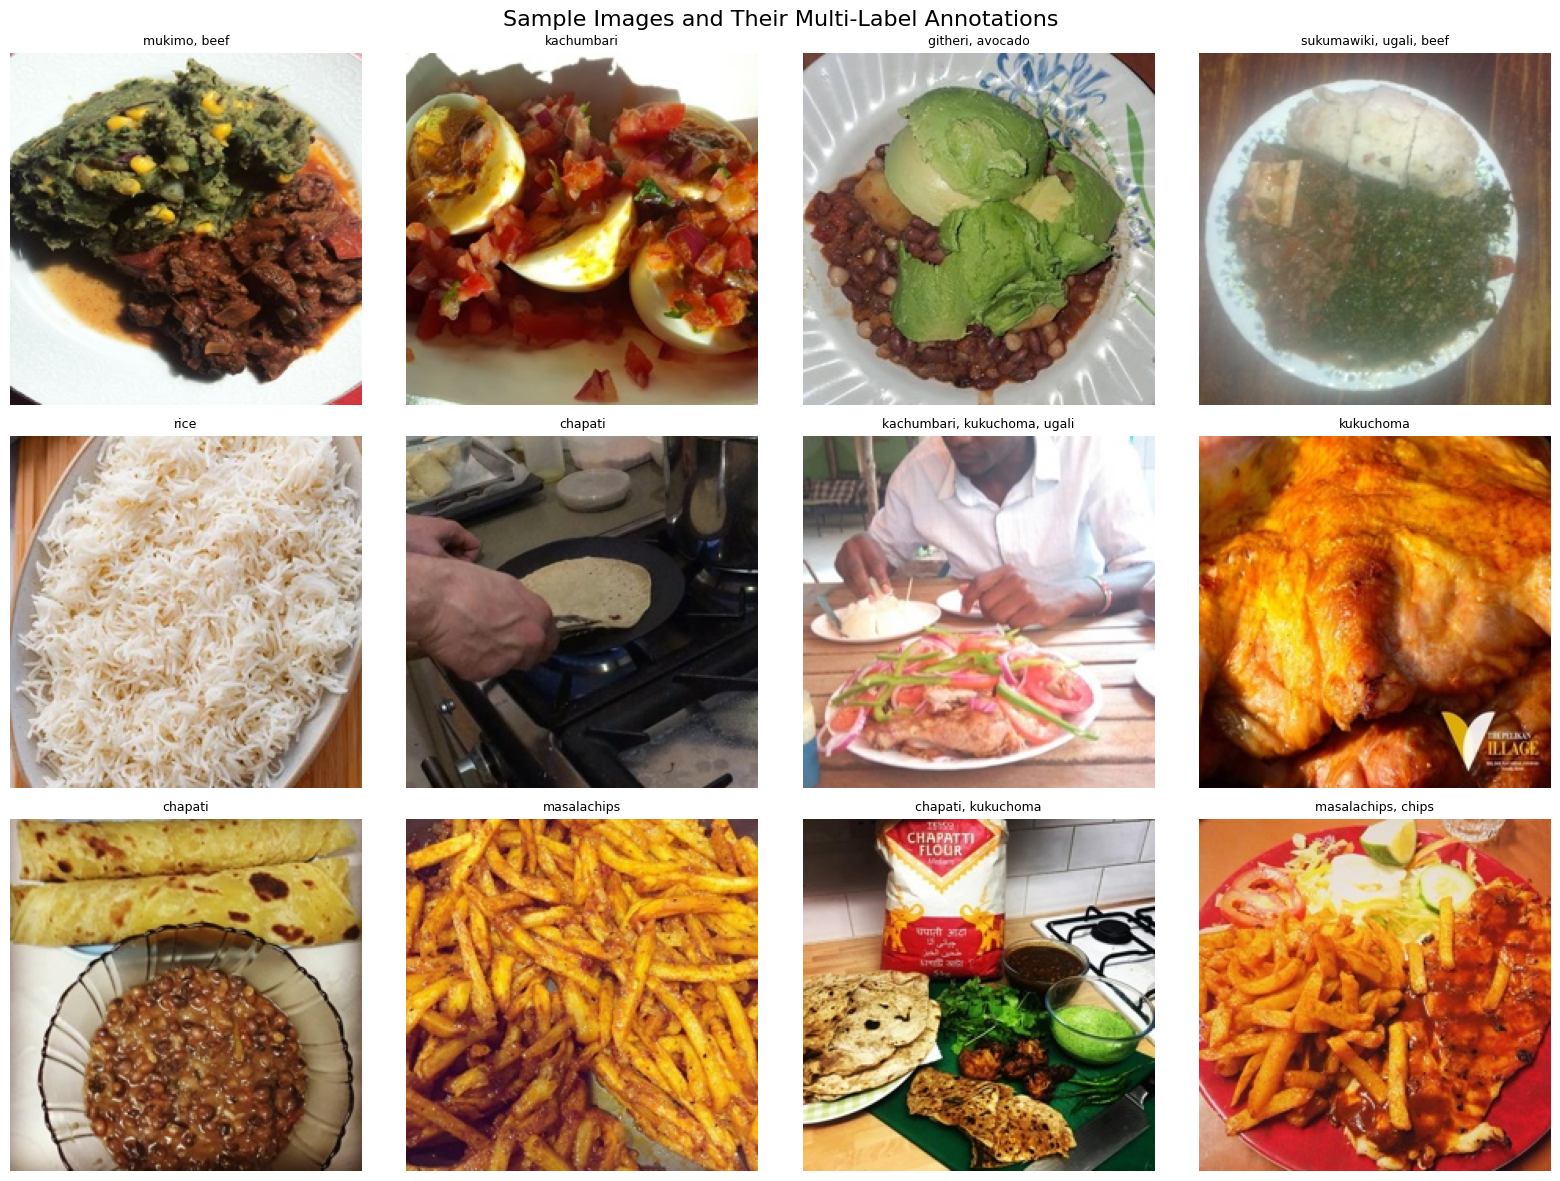

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image

# Load the final annotation dataset
CSV_PATH = "/content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_final_v1.csv"

df = pd.read_csv(CSV_PATH)

# Identify metadata columns
metadata_columns = [
    "image_id", "filename", "image_filename", "image_path",
    "original_folder", "original_category",
    "annotation_status", "reviewed", "annotator", "notes"
]

# Identify food label columns
label_columns = [
    col for col in df.columns
    if col not in metadata_columns
    and set(df[col].dropna().unique()).issubset({0, 1})
]

# Select up to 12 images
sample_df = df.sample(
    n=min(12, len(df)),
    random_state=42
)

# Display images and their annotations
plt.figure(figsize=(16, 12))

for i, (_, row) in enumerate(sample_df.iterrows()):
    image_path = row["image_path"]

    plt.subplot(3, 4, i + 1)

    if os.path.exists(image_path):
        image = Image.open(image_path).convert("RGB")
        plt.imshow(image)

        # Get all positive food labels
        labels = [
            label for label in label_columns
            if row[label] == 1
        ]

        plt.title(", ".join(labels), fontsize=9)
    else:
        plt.text(0.5, 0.5, "Image not found",
                 ha="center", va="center")

    plt.axis("off")

plt.suptitle(
    "Sample Images and Their Multi-Label Annotations",
    fontsize=16
)

plt.tight_layout()
plt.show()

### 2.5 Annotation Challenges and Observations

During the annotation process, particular attention was given
to foods that could easily be confused with other categories.

Some of the important considerations included:

1. Rice and Pilau:
   Plain rice and pilau can have similar visual appearances.
   Images were therefore examined carefully to distinguish
   between the two categories.

2. Githeri and Beans:
   Githeri contains a mixture of ingredients, including beans
   and maize. The presence of beans alone was not sufficient
   to classify an image as githeri. The overall food composition
   was considered during annotation.

3. Multiple Food Items:
   Some images contained more than one identifiable food item.
   These images were assigned multiple labels where appropriate.

4. Annotation Corrections:
   The annotation records were reviewed and corrected where
   necessary to improve consistency. This included reviewing
   Matoke annotations and correcting the avocado annotation
   for the image named Githeri_spinach_avacado.jpg.

These considerations helped improve the quality and consistency
of the labelled dataset before model development.

# 3. Data Cleaning and Preprocessing

## 3.1 Image Selection and Annotation

The original dataset contained 6,462 standardised images
across 13 Kenyan food categories.

However, the original dataset was designed for single-label
classification, meaning images were initially organised
according to one food category.

Since the new project adopted a multi-label classification
approach, the images needed to be reviewed and annotated
according to the food items actually visible in each image.

An image auditing and annotation process was therefore
carried out. Images were examined individually, and the
presence of each food category was recorded using binary
labels.

A value of 1 represented the presence of a food category,
while a value of 0 represented its absence.

Images that were unclear or unsuitable were not treated
as reliable training examples. The original dataset was
preserved while unsuitable images were excluded from
the final annotated dataset.

The resulting curated dataset contained 639 images
with 22 food label columns.

### 3.2 Dataset Integrity Checks

After completing the annotation process, the final dataset
was subjected to several integrity checks.

The checks were intended to identify:

- Duplicate image paths.
- Missing image files.
- Missing annotation values.
- Invalid label values.
- Incorrect dataset split assignments.

These checks were important because missing images,
duplicate records or incorrectly formatted labels could
negatively affect the training process.

The final annotation dataset was stored in a CSV file
named `combined_annotations_final_v1.csv`.

In [ ]:
import pandas as pd
import os

# Load final annotated dataset
CSV_PATH = "/content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_final_v1.csv"

df = pd.read_csv(CSV_PATH)

# Define the 22 food labels
label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Check for duplicate image paths
duplicate_paths = df["image_path"].duplicated().sum()

# Check for missing image files
missing_files = sum(
    not os.path.exists(path)
    for path in df["image_path"]
)

# Check for missing label values
missing_labels = df[label_columns].isnull().sum().sum()

# Check for invalid label values
invalid_values = {}

for col in label_columns:
    invalid = df.loc[
        ~df[col].isin([0, 1]), col
    ].unique().tolist()

    if len(invalid) > 0:
        invalid_values[col] = invalid

# Display results
print("DATASET INTEGRITY REPORT")
print("------------------------")
print("Total images:", len(df))
print("Total food labels:", len(label_columns))
print("Duplicate image paths:", duplicate_paths)
print("Missing image files:", missing_files)
print("Missing label values:", missing_labels)
print("Invalid label values:", invalid_values)

print("\nDataset split distribution:")
print(df["split"].value_counts())


DATASET INTEGRITY REPORT
------------------------
Total images: 639
Total food labels: 22
Duplicate image paths: 0
Missing image files: 0
Missing label values: 0
Invalid label values: {}

Dataset split distribution:
split
train         431
test          117
validation     91
Name: count, dtype: int64


### 3.3 Training, Validation and Testing Split

The final annotated dataset was divided into three subsets
for model development and evaluation.

The training dataset contained 431 images and was used
to teach the model to recognise the different food categories.

The validation dataset contained 91 images and was used
to monitor the model's performance during training and
help assess its ability to generalise to unseen examples.

The testing dataset contained 117 images and was reserved
for the final evaluation of the trained model.

The resulting split was:

- Training: 431 images
- Validation: 91 images
- Testing: 117 images

This separation ensured that the final test results
were based on images that were not used to train the model.

DATASET SPLIT SUMMARY
---------------------
Train: 431 images
Validation: 91 images
Test: 117 images


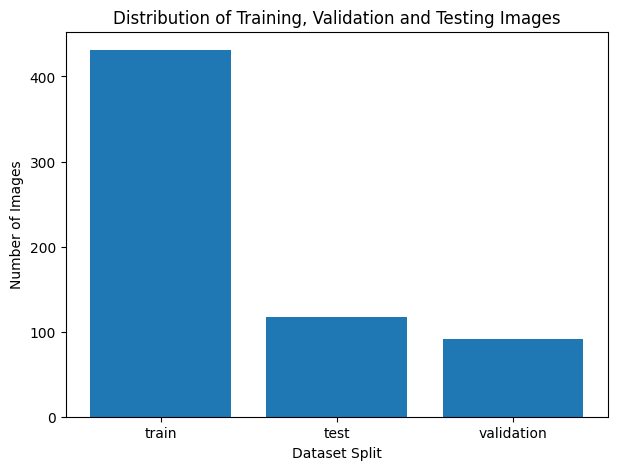

In [ ]:
# Display the number of images in each dataset split

split_counts = df["split"].value_counts()

print("DATASET SPLIT SUMMARY")
print("---------------------")

for split_name in ["train", "validation", "test"]:
    print(f"{split_name.capitalize()}: {split_counts.get(split_name, 0)} images")

# Visualise the split distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(split_counts.index, split_counts.values)

plt.title("Distribution of Training, Validation and Testing Images")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")

plt.show()

### 3.4 Image Preprocessing

Before being used for training, the images underwent
preprocessing to ensure consistency.

The following preprocessing operations were applied:

1. Image loading: Images were loaded using their recorded
   file paths in the annotation dataset.

2. Colour conversion: Images were decoded in RGB format
   to ensure consistent colour representation.

3. Resizing: All images were resized to 224 × 224 pixels.
   This ensured that every image had the same dimensions
   required by the MobileNetV2 architecture.

4. Pixel preprocessing: The images were converted into
   numerical tensors and prepared for the model using
   the appropriate preprocessing function.

5. Batching and performance optimisation: Images were
   organised into batches, and dataset prefetching was
   used to improve the efficiency of the training pipeline.

These operations ensured that the images could be
consistently processed by the neural network.

# 4. Model Development

## 4.1 Model Architecture Selection

For this project, MobileNetV2 was selected as the base
architecture for the image classification model.

MobileNetV2 is a Convolutional Neural Network (CNN)
architecture designed for efficient image recognition.
It uses depthwise separable convolutions and inverted
residual connections to reduce computational complexity
while maintaining effective feature extraction.

The project uses transfer learning, where a pre-trained
MobileNetV2 model is used as the foundation for recognising
Kenyan food categories.

The pre-trained weights were obtained from ImageNet.
The original classification layer was removed by setting
`include_top=False`, allowing the network to be adapted
to our specific food classification task.

Initially, the pre-trained MobileNetV2 layers were frozen
so that their existing visual feature representations
could be retained while the new classification layers
were trained.

This approach reduced the amount of training required
compared to building an entirely new CNN from scratch.

### 4.2 Model Input and Configuration

The model was configured to accept RGB images with
dimensions of 224 × 224 pixels.

The following configuration was used:

- Input image size: 224 × 224 pixels.
- Colour channels: 3 (RGB).
- Batch size: 32.
- Number of output labels: 22.
- Pre-trained weights: ImageNet.
- Base architecture: MobileNetV2.

The images were processed using the MobileNetV2
preprocessing function, which scales the pixel values
to the range expected by the pre-trained network.

The model also incorporated data augmentation techniques
to introduce variation into the training images and
help reduce overfitting.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Number of food labels
NUM_CLASSES = 22

# Input image dimensions
IMG_SIZE = (224, 224)

# Define data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
])

# Load pre-trained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pre-trained layers
base_model.trainable = False

# Define model input
inputs = layers.Input(shape=(224, 224, 3))

# Apply data augmentation
x = data_augmentation(inputs)

# Apply MobileNetV2 preprocessing
x = preprocess_input(x)

# Extract image features
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

# Final multi-label output layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="sigmoid"
)(x)

# Create the complete model
model = models.Model(inputs, outputs)

# Display model architecture
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,574 (9.89 MB)

 Trainable params: 333,590 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 4.4 Explanation of the Model Architecture

The model consists of several components:

**1. Data Augmentation**

Three augmentation techniques were introduced:

- Random Flip: Horizontally flips images to introduce
  variation in food orientation.
- Random Rotation: Rotates images slightly to help the
  model recognise food from different angles.
- Random Zoom: Randomly zooms into images to introduce
  variation in the size and positioning of food items.

**2. MobileNetV2 Feature Extraction**

The pre-trained MobileNetV2 network extracts important
visual features from the input images.

The original classification layer was removed, and the
pre-trained layers were initially frozen.

**3. Global Average Pooling**

GlobalAveragePooling2D reduces the spatial dimensions
of the extracted feature maps into a single feature vector.

**4. Dropout Layers**

Two dropout layers with a rate of 0.3 were introduced
to reduce overfitting by randomly disabling some neurons
during training.

**5. Dense Layer**

A fully connected layer containing 256 neurons with
ReLU activation was added to learn combinations of
the extracted visual features.

**6. Output Layer**

The final layer contains 22 neurons, corresponding
to the 22 food labels.

A sigmoid activation function was used because this is
a multi-label classification problem. Each output neuron
produces an independent probability between 0 and 1.

This allows the model to predict multiple food categories
for a single image.

### 4.5 Model Compilation

After constructing the architecture, the model was
compiled using the Adam optimisation algorithm.

Binary Cross-Entropy was selected as the loss function
because the model performs multi-label classification.

Unlike categorical cross-entropy, which assumes that
only one class is correct, binary cross-entropy evaluates
each output label independently.

The following evaluation metrics were included:

- Binary Accuracy
- AUC (Area Under the Curve)
- Precision
- Recall

These metrics provide different perspectives on the
model's classification performance.

In [ ]:
# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=NUM_CLASSES
        ),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


# 5. Model Training

## 5.1 Training Configuration

After developing and compiling the MobileNetV2 architecture,
the model was prepared for training.

The dataset was divided into training, validation and testing
subsets.

The training dataset contained 431 images, while the
validation dataset contained 91 images. The remaining
117 images were reserved for testing.

A batch size of 32 was used to process images during training.

The model was trained using the Adam optimisation algorithm,
with a learning rate of 0.001.

Binary Cross-Entropy was selected as the loss function
for the multi-label classification task.

During training, the model learned to identify visual
features associated with the different Kenyan food categories.
Its performance was monitored using the validation dataset.

### 5.2 Training Callbacks

Callbacks were incorporated into the training workflow
to help monitor the model's performance and manage
the training process.

The training workflow included mechanisms for monitoring
validation loss, adjusting the learning rate and saving
the best-performing model.

Early stopping can also be used to prevent unnecessary
training when validation performance stops improving.

These mechanisms help manage training time and reduce
the risk of overfitting.

### 5.3 Model Training Process

The model was trained using the prepared training dataset,
with the validation dataset used to monitor its performance.

During each epoch, the model processed batches of images,
generated predictions and adjusted its trainable parameters
based on the calculated loss.

After each epoch, the model's performance was evaluated
against the validation dataset.

The training history was recorded to allow the analysis
of changes in loss and evaluation metrics throughout
the training process.

In [ ]:
history = multilabel_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - auc: 0.5383 - binary_accuracy: 0.8208 - loss: 0.7108 - val_auc: 0.6971 - val_binary_accuracy: 0.9071 - val_loss: 0.5771 - learning_rate: 0.0010
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - auc: 0.7083 - binary_accuracy: 0.8847 - loss: 0.5564 - val_auc: 0.7784 - val_binary_accuracy: 0.9116 - val_loss: 0.5270 - learning_rate: 0.0010
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - auc: 0.7931 - binary_accuracy: 0.9072 - loss: 0.4828 - val_auc: 0.8202 - val_binary_accuracy: 0.9251 - val_loss: 0.4811 - learning_rate: 0.0010
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - auc: 0.8526 - binary_accuracy: 0.9128 - loss: 0.4282 - val_auc: 0.8482 - val_binary_accuracy: 0.9231 - val_loss: 0.4572 - learning_rate: 0.0010
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - auc: 0.8728 - binary_accuracy: 0.9205 - loss: 0.3934 - val_auc: 0.8550 - val_binary_accuracy: 0.9261 - val_loss: 0.4326 - learning_rate: 0.0010
Epoch 6/15
14/14 ━━━

### 5.4 Training Results

The training history was used to examine how the model
performed throughout the training process.

Training and validation loss were monitored to determine
whether the model was learning effectively.

The evaluation metrics recorded during training were
also examined to assess the model's ability to identify
the different food categories.

The saved model checkpoint was retained for subsequent
evaluation and prediction tasks.

# 6. Model Evaluation

## 6.1 Loading the Trained Model

After completing the training process, the saved model
was loaded for evaluation.

The model was evaluated using a separate testing dataset
that was not used during the training process.

This allowed us to assess how well the model generalised
to previously unseen food images.

The trained MobileNetV2 model retained its 22 output
labels, allowing it to generate independent probability
scores for each food category.

### 6.2 Test Dataset Evaluation

The testing dataset was used to evaluate the performance
of the trained model.

The model generated predictions for the test images,
which were subsequently compared against their actual
annotations.

This evaluation provided an indication of how effectively
the model could identify the different food categories
in previously unseen images.

The evaluation considered the model's loss and relevant
multi-label classification metrics.

### 6.3 Classification Performance

To obtain a more detailed understanding of the model's
performance, additional classification metrics were
examined.

The following metrics were considered:

1. Precision: Measures how many of the food categories
   predicted by the model were actually present.

2. Recall: Measures how many of the actual food categories
   were successfully identified by the model.

3. F1-score: Provides a balance between precision and
   recall.

These metrics are particularly useful for multi-label
classification because the model must independently
identify multiple possible food categories in an image.

The results were also examined at individual label level
to identify categories that the model recognised well
and those that required further improvement.

### 6.4 Comparison of Original and Tuned Performance

A comparison between the original and threshold-tuned
results demonstrated an improvement in classification
performance.

The Micro F1-score increased from 0.494 to 0.621,
while the Macro F1-score increased from 0.472 to 0.621.

This represents an improvement of 0.127 in Micro F1
and 0.149 in Macro F1.

The improvement in Macro F1-score is particularly
noteworthy because it indicates better average
performance across the individual food categories.

Threshold tuning therefore provided a more suitable
classification approach for the imbalanced multi-label
dataset.

However, these results were obtained using the validation
dataset and should not be interpreted as final test
performance.

### 6.5 Prediction Error Analysis

Following the evaluation and threshold tuning stages,
a prediction error analysis was conducted to investigate
the model's classification mistakes.

Individual images were examined by comparing their actual
food annotations with the categories predicted by the model.

The analysis focused on identifying:

- False positives: Food categories incorrectly predicted
  as present.
- False negatives: Food categories that were present
  but were not identified by the model.
- Correct predictions: Food categories correctly
  identified by the model.

This investigation helped identify categories that
were difficult for the model to distinguish and provided
a better understanding of its limitations.

### 6.5.2 Analysis of Difficult Food Categories

The prediction analysis revealed that certain food
categories presented greater classification challenges.

Particular attention was given to categories with
similar visual characteristics or overlapping ingredients.

For example:

1. Rice and Pilau:
   These foods can have similar visual characteristics,
   making them difficult to distinguish in some images.

2. Githeri and Beans:
   Githeri contains beans and maize. Consequently,
   images containing beans required careful examination
   to determine whether they represented githeri or
   beans as a separate food category.

3. Other Food Categories:
   Some categories also presented challenges due to
   limited training examples, visual similarities and
   differences in image quality.

The findings demonstrated that classification errors
were not necessarily caused by the model architecture
alone. Dataset composition, image characteristics
and annotation quality also influenced performance.

### 6.5.3 Investigation of the Chips Category

The Chips category was examined separately because
of its poor classification performance.

During validation, the category achieved an F1-score
of 0.000, indicating that the model was unable to
correctly identify its positive examples at the
default classification threshold.

Threshold tuning did not improve its F1-score.

Following further investigation of the prediction
examples, it was decided that Chips would be excluded
from the reported classification results.

However, the original model architecture retained
its 22 output neurons. The exclusion applied to the
reported analysis and did not involve retraining
the model with 21 output categories.

### 6.5.4 Summary of Error Analysis

The prediction error analysis provided further insight
into the strengths and limitations of the model.

The investigation highlighted the importance of
accurate annotations, sufficient training examples
and the visual similarities between certain Kenyan
food categories.

It also demonstrated that threshold tuning could
improve classification performance, although it
could not resolve every classification problem.

The findings were considered when determining which
food categories could be reliably evaluated and
which required further investigation.

# 7. Conclusion

This project involved developing a multi-label image classification model for identifying Kenyan foods from images. The model was built using MobileNetV2 with ImageNet pre-trained weights and adapted to predict 22 food labels using sigmoid activation. Unlike a single-label classifier, the model can identify multiple food items within the same image.

The dataset consisted of 639 annotated images, divided into 431 training images, 91 validation images and 117 test images. During development, image inspection, annotation corrections and data validation were carried out to improve the quality and consistency of the dataset.

The validation results showed that the model could identify several food categories effectively. After applying class-specific threshold tuning, the validation Micro F1-score improved from 0.494 to 0.621, while the Macro F1-score improved from 0.472 to 0.621. This demonstrated that adjusting prediction thresholds for individual food categories improved the model's validation performance.

However, some challenges remained. Certain foods have similar visual characteristics, making them difficult to distinguish. Categories such as rice and pilau, as well as githeri and beans, required careful annotation because of their similarities and overlapping ingredients. Some categories also had very few annotated examples, which limited the reliability of their evaluation results. Chips remained a particularly difficult category for the model.

Overall, the project demonstrated the potential of transfer learning and multi-label classification for recognising Kenyan foods. Although the model still has limitations, the results provide a useful foundation for further improvements through collecting more diverse images, improving annotation quality and expanding the dataset.

## Group Members

| Student ID | Name |
|---|---|
| 189719 | Caleb Munene |
| 184066 | Dalton Mule |
| 176830 | Wachira Ivan |